# **Text Vectorization I: Sparse Representations**

---
### Natural Language Processing — Master in Applied Artificial Intelligence

Authors: Jerónimo Arenas-García (jarenas@ing.uc3m.es), Lorena Calvo-Bartolomé (lcalvo@pa.uc3m.es), Jesús Cid-Sueiro (jcid@ing.uc3m.es)

Version 2.0 (November 2026). First version: November 2022.

---

Our goal here is to provide a basic overview of the following aspects:

*   NLP preprocessing
*   Document BoW and TF-IDF representations
*   Using them to solve a text classification task
*   Using them for **document retrieval** (TF-IDF and BM25), evaluated with Recall@K and MRR

**How to work with this notebook:** we will start it in the lab session of **Thursday, November 12**. Section 4 (retrieval) is the template for **Milestone 1** of the course project, where you will build and evaluate the same kind of baseline on your own corpus.

Before this notebook, you should have worked on the notebook *Using spaCy for Text Preprocessing*.

In [ ]:
# Common imports
import os
import json
import numpy as np
import pandas as pd
from termcolor import colored
import seaborn as sns
import matplotlib.pyplot as plt

# Figures plotted inside the notebook
%matplotlib inline
# High quality figures
%config InlineBackend.figure_format = 'retina'
# Figures style
sns.set_style("darkgrid")
# Figures size
plt.rcParams['figure.figsize'] = [8, 6]

In [ ]:
# Colab-specific helpers (they are skipped when running the notebook elsewhere)
import sys
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    # Fancy (interactive) display of dataframes
    get_ipython().run_line_magic('load_ext', 'google.colab.data_table')

# To wrap long text lines in outputs
from IPython.display import HTML, display
def set_css(*args, **kwargs):
    display(HTML('<style> pre { white-space: pre-wrap; } </style>'))
get_ipython().events.register('pre_run_cell', set_css)

In [ ]:
# Packages that are not preinstalled in Google Colab
%pip install --quiet gensim bm25s contractions
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 49.4 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


### Data files

The data files for this notebook are available on Aula Global. Copy them to a folder in your Google Drive and update `DATA_DIR` accordingly:

* `imdb_reviews_10k.csv`: 10,000 reviews from the **IMDB Dataset of 50K Movie Reviews**, with their sentiment
* `imdb_queries.jsonl`: a set of test queries for the retrieval section

The files generated by this notebook will be saved in the same folder; you will need them in the Text Vectorization II notebook.

In [ ]:
DATA_DIR = 'NLP_data'   # folder with the course data files when running locally

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = '/content/drive/My Drive/PLN/NLP_data'  # UPDATE THIS ACCORDING TO WHERE YOU STORED THE FILES!!!!

print(os.listdir(DATA_DIR))

Mounted at /content/drive
['corpus_df_imdb.csv', 'imdb_lemmas_clean.txt', 'imdb_queries.jsonl', 'imdb_reviews_10k.csv']


## **1. Data preparation**
---

### *1.1. Data loading*

We will be using a sample of 10,000 reviews from the **IMDB Dataset of 50K Movie Reviews**. The dataset is oriented toward binary sentiment classification, i.e., predicting whether each review is positive or negative.

The dataframe has three columns: `id` (an identifier of the review in the original dataset), `review`, which contains the text, and `sentiment`, which contains the labels. We will work first on the `review` column to apply different types of text vectorization; then we will use the `sentiment` column for the sentiment analysis task, and the `id` column for the retrieval task.

In [ ]:
corpus_df = pd.read_csv(os.path.join(DATA_DIR, 'imdb_reviews_10k.csv'))
print(len(corpus_df))
print(corpus_df['sentiment'].value_counts())
corpus_df.head()

10000
sentiment
negative    5036
positive    4964
Name: count, dtype: int64


,id,review,sentiment
0,1,A wonderful little production. <br /><br />The...,positive
1,9,If you like original gut wrenching laughter yo...,positive
2,14,This a fantastic movie of three prisoners who ...,positive
3,18,"I remember this film,it was the first film i h...",positive
4,20,After the success of Die Hard and it's sequels...,positive


### *1.2. Preprocessing a review step by step*

Before continuing with the vectorization task, we should structure and clean the text so that we only keep the information that allows us to capture the semantic content of the corpus.

We will first apply the following four steps to a single review, which are typical of any NLP preprocessing task:

1.   Text wrangling
2.   Tokenization
3.   Homogenization
4.   Cleaning

For these steps, we will be using some methods available from:

*   [Natural Language Toolkit](https://www.nltk.org/)
*   [Beautiful Soup](https://pypi.org/project/beautifulsoup4/)
*   [Contractions](https://pypi.org/project/contractions/)
*   [re — Regular expression operations](https://docs.python.org/3/library/re.html)

Then, in Section 1.3, we will implement the whole pipeline for the corpus with spaCy, as in the spaCy notebook.

In [ ]:
import re
import nltk

# Recent NLTK versions need 'punkt_tab' for sentence tokenization
for package in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'omw-1.4']:
    nltk.download(package, quiet=True)

import contractions
from bs4 import BeautifulSoup

#### *1.2.1. Text Wrangling*

If we inspect the reviews, we can see that they contain many HTML tags and some URLs that we do not want to keep for our text vectorization task since they don't add much value for understanding and analyzing the text.

Additionally, there are many English contractions ('ll, 're) that we would like to transform into their base form (will, are) to later help with the standardization process.

##### **Exercise 1**

Complete the function ``wrangle_text`` that performs the text wrangling task. For doing so:

*   Make use of the library ``BeautifulSoup`` with the parser ``"lxml"`` to get rid of all HTML tags.
*   Use the function ``re.sub`` to remove all URLs in text. To this function, we need to provide a **regular expression**, i.e., a special sequence of characters that help us match or find other strings or sets of strings, using a specialized syntax held in a pattern, and a string to replace the occurrences of the regular expression found. Typically, we would use define the regular expressions as raw strings in the form r'expression'.
You can identify URLs using the pattern ``r'https://\S+|www\.\S+'``.
* Use the method ``fix`` from the ``contractions`` library to expand the contractions.

Apply the ``wrangle_text`` function into the first positive ``review`` in the corpus and save the result into a variable named ``wrangled_review``. Print the review before and after making the text wrangling.


In [ ]:
#<SOL>
def wrangle_text(text):
    # 1. Quitar las etiquetas HTML con BeautifulSoup (parser lxml)
    text = BeautifulSoup(text, 'lxml').get_text()
    # 2. Quitar las URLs con una expresión regular
    text = re.sub(r'https://\S+|www\.\S+', '', text)
    # 3. Expandir las contracciones (I'll -> I will)
    text = contractions.fix(text)
    return text
#</SOL>

print(colored('\n============= First review in corpus =============', 'blue'))

#<SOL>
# Primera reseña positiva del corpus
first_review = corpus_df[corpus_df['sentiment'] == 'positive']['review'].iloc[0]
print(first_review)
#</SOL>

print(colored('\n============= After wrangling result =============', 'blue'))

#<SOL>
wrangled_review = wrangle_text(first_review)
print(wrangled_review)
#</SOL>


============= First review in corpus =============
A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. <br /><br />The actors are extremely well chosen- Michael Sheen not only "has got all the polari" but he has all the voices down pat too! You can truly see the seamless editing guided by the references to Williams' diary entries, not only is it well worth the watching but it is a terrificly written and performed piece. A masterful production about one of the great master's of comedy and his life. <br /><br />The realism really comes home with the little things: the fantasy of the guard which, rather than use the traditional 'dream' techniques remains solid then disappears. It plays on our knowledge and our senses, particularly with the scenes concerning Orton and Halliwell and the sets (particularly of their flat with Halliwell's murals

#### *1.2.2. Tokenization*

Tokenization is the process of segmenting a text into words,
referred to as **tokens**. This procedure will often also break off punctuation symbols (commas, periods, etc.), phrases, and other possible meaningful elements from the text, such as separate tokens. The list of tokens resulting from tokenization becomes the input for the homogenization stage.

The [NLTK Tokenizer Package](https://www.nltk.org/api/nltk.tokenize.html) offers several functions to perform tokenization operations on any text string. Here we will be using the ``wordpunct_tokenize`` function, which allows the separation of punctuation marks. Since sometimes we will be interested in performing the tokenization at the sentence level, we can combine ``wordpunct_tokenize`` and ``sent_tokenize``.

##### **Exercise 2**

* Tokenize the ``wrangled_review`` at the word level using the ``wordpunct_tokenize`` function. Save the tokenized review in a variable named ``review_tokens``.
* Tokenize the the ``wrangled_review`` at the sentence level using the combination of ``wordpunct_tokenize`` and  ``sent_tokenize`` functions. Save the tokenized review in a variable named ``review_tokens_sent``.

In [ ]:
from nltk.tokenize import wordpunct_tokenize
from nltk.tokenize import sent_tokenize

print(colored('\n============= First review in corpus =============', 'blue'))
print(wrangled_review)

#<SOL>
# Nivel palabra: lista de tokens de toda la reseña
review_tokens = wordpunct_tokenize(wrangled_review)

# Nivel frase: primero partimos en frases y luego tokenizamos cada una
review_tokens_sent = [wordpunct_tokenize(sent) for sent in sent_tokenize(wrangled_review)]
#</SOL>

print(colored('\n============= First review (tokens) =============', 'blue'))
print(review_tokens)

print(colored('\n============= First review (tokens sent level) =============', 'blue'))
print(review_tokens_sent)


============= First review in corpus =============
A wonderful little production. The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. The actors are extremely well chosen- Michael Sheen not only "has got all the polari" but he has all the voices down pat too! You can truly see the seamless editing guided by the references to Williams' diary entries, not only is it well worth the watching but it is a terrificly written and performed piece. A masterful production about one of the great master's of comedy and his life. The realism really comes home with the little things: the fantasy of the guard which, rather than use the traditional 'dream' techniques remains solid then disappears. It plays on our knowledge and our senses, particularly with the scenes concerning Orton and Halliwell and the sets (particularly of their flat with Halliwell's murals decorating every surface) are terri

#### *1.2.3. Homogenization*

Homogenization is the process that aims to collapse all semantically equivalent words into a unique representative one. For example, `develop`, `development`, `developing`, `developed`, `developer`, `developmental`, and `developmentally` share the same root and, therefore, have a certain relationship of meaning.

To homogenize the set of tokens obtained in the previous stage, the following steps need to be performed:

1.   **Lowercasing the tokens**
2.   **Elimination of non-alphanumeric characters**, like periods, question marks, and exclamation points
3.   **Word normalization (stemming/lemmatization)**

Let's see how to apply each of these steps to the previously selected review.

##### **Exercise 3**

Perform the following two transformations to ``review_tokens``:

1.   Convert the tokens to lowercase. Use the ``.lower()`` method.
2.   Remove non-alphanumeric tokens. You can detect them using the ``.isalnum()`` method.

Save the result in a variable named ``review_tokens_filtered``.

In [ ]:
#<SOL>
# 1. Pasamos todos los tokens a minúsculas
# 2. Nos quedamos solo con los alfanuméricos (fuera la puntuación)
review_tokens_filtered = [tk.lower() for tk in review_tokens if tk.isalnum()]
#</SOL>

At this point, we can choose between stemming and lemmatization. We will try NLTK's Snowball stemmer and WordNet lemmatizer, and compare them with spaCy's lemmatizer.

In [ ]:
from nltk.stem import SnowballStemmer
from nltk.stem import WordNetLemmatizer

stemmer = SnowballStemmer('english')
wnl = WordNetLemmatizer()

stemmed_review = [stemmer.stem(el) for el in review_tokens_filtered]
print(colored('\n============= Stemmed review  =============', 'blue'))
print(stemmed_review)

lemmatized_review = [wnl.lemmatize(el) for el in review_tokens_filtered]
print(colored('\n============= Lemmatized review  =============', 'blue'))
print(lemmatized_review)


============= Stemmed review  =============
['a', 'wonder', 'littl', 'product', 'the', 'film', 'techniqu', 'is', 'veri', 'unassum', 'veri', 'old', 'time', 'bbc', 'fashion', 'and', 'give', 'a', 'comfort', 'and', 'sometim', 'discomfort', 'sens', 'of', 'realism', 'to', 'the', 'entir', 'piec', 'the', 'actor', 'are', 'extrem', 'well', 'chosen', 'michael', 'sheen', 'not', 'onli', 'has', 'got', 'all', 'the', 'polari', 'but', 'he', 'has', 'all', 'the', 'voic', 'down', 'pat', 'too', 'you', 'can', 'truli', 'see', 'the', 'seamless', 'edit', 'guid', 'by', 'the', 'refer', 'to', 'william', 'diari', 'entri', 'not', 'onli', 'is', 'it', 'well', 'worth', 'the', 'watch', 'but', 'it', 'is', 'a', 'terrif', 'written', 'and', 'perform', 'piec', 'a', 'master', 'product', 'about', 'one', 'of', 'the', 'great', 'master', 's', 'of', 'comedi', 'and', 'his', 'life', 'the', 'realism', 'realli', 'come', 'home', 'with', 'the', 'littl', 'thing', 'the', 'fantasi', 'of', 'the', 'guard', 'which', 'rather', 'than', 'use',

One of the advantages of lemmatization is that the result is still a true word. However, NLTK's WordNet lemmatizer, used without part-of-speech (POS) information, treats every token as a noun: it does not remove grammatical differences (e.g., *is* is not replaced by *be*), and it makes mistakes such as *as* $\rightarrow$ *a* or *does* $\rightarrow$ *doe*.

spaCy's lemmatizer uses the POS tag predicted for each token in its context, so it avoids these errors:

In [ ]:
import spacy
nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])

spacy_lemmas = [tk.lemma_.lower() for tk in nlp(wrangled_review) if tk.text.isalnum()]
print(colored('\n============= spaCy lemmatized review  =============', 'blue'))
print(spacy_lemmas)

differences = sorted(set([(w, l) for w, l in zip(review_tokens_filtered, lemmatized_review) if w in ('is', 'was', 'as', 'does', 'has')]))
print(colored('\n============= Some WordNet lemmas without POS =============', 'red'))
print(differences)


============= spaCy lemmatized review  =============
['a', 'wonderful', 'little', 'production', 'the', 'filming', 'technique', 'be', 'very', 'very', 'old', 'time', 'bbc', 'fashion', 'and', 'give', 'a', 'comforting', 'and', 'sometimes', 'discomforte', 'sense', 'of', 'realism', 'to', 'the', 'entire', 'piece', 'the', 'actor', 'be', 'extremely', 'well', 'michael', 'sheen', 'not', 'only', 'have', 'get', 'all', 'the', 'polari', 'but', 'he', 'have', 'all', 'the', 'voice', 'down', 'pat', 'too', 'you', 'can', 'truly', 'see', 'the', 'seamless', 'editing', 'guide', 'by', 'the', 'reference', 'to', 'williams', 'diary', 'entry', 'not', 'only', 'be', 'it', 'well', 'worth', 'the', 'watching', 'but', 'it', 'be', 'a', 'terrificly', 'write', 'and', 'perform', 'piece', 'a', 'masterful', 'production', 'about', 'one', 'of', 'the', 'great', 'master', 'of', 'comedy', 'and', 'his', 'life', 'the', 'realism', 'really', 'come', 'home', 'with', 'the', 'little', 'thing', 'the', 'fantasy', 'of', 'the', 'guard', 'wh

#### *1.2.4. Cleaning*

The third step consists of removing those words that are very common in language and do not carry out useful semantic content (articles, pronouns, etc.). For it, we will use the list of stopwords provided by NLTK.

##### **Exercise 4**

Clean ``lemmatized_review`` by removing all tokens in the stopwords list ``stopwords_en``. Save the result in a variable named ``clean_review``.


In [ ]:
from nltk.corpus import stopwords
stopwords_en = set(stopwords.words('english'))

#<SOL>
# Nos quedamos con los lemas que no están en la lista de stopwords
clean_review = [w for w in lemmatized_review if w not in stopwords_en]
#</SOL>

print(colored('\n============= Lemmatized review  =============', 'blue'))
print(lemmatized_review)
print(colored('\n============= Clean lemmatized review  =============', 'blue'))
print(clean_review)


============= Lemmatized review  =============
['a', 'wonderful', 'little', 'production', 'the', 'filming', 'technique', 'is', 'very', 'unassuming', 'very', 'old', 'time', 'bbc', 'fashion', 'and', 'give', 'a', 'comforting', 'and', 'sometimes', 'discomforting', 'sense', 'of', 'realism', 'to', 'the', 'entire', 'piece', 'the', 'actor', 'are', 'extremely', 'well', 'chosen', 'michael', 'sheen', 'not', 'only', 'ha', 'got', 'all', 'the', 'polari', 'but', 'he', 'ha', 'all', 'the', 'voice', 'down', 'pat', 'too', 'you', 'can', 'truly', 'see', 'the', 'seamless', 'editing', 'guided', 'by', 'the', 'reference', 'to', 'williams', 'diary', 'entry', 'not', 'only', 'is', 'it', 'well', 'worth', 'the', 'watching', 'but', 'it', 'is', 'a', 'terrificly', 'written', 'and', 'performed', 'piece', 'a', 'masterful', 'production', 'about', 'one', 'of', 'the', 'great', 'master', 's', 'of', 'comedy', 'and', 'his', 'life', 'the', 'realism', 'really', 'come', 'home', 'with', 'the', 'little', 'thing', 'the', 'fantasy'

### *1.3. Preprocessing the whole corpus with spaCy*

For the whole corpus, we will use spaCy, as in Exercise 7 of the spaCy notebook: lemmatization uses POS information, we can keep only content words, and `nlp.pipe` processes the collection efficiently.

##### **Exercise 5**

Complete the function `prepare_data`, which receives a list of raw texts and returns a list with the clean lemmas of each text. For each text, it must:

1. Apply `wrangle_text`
2. Process the texts with `nlp.pipe` (the parser and NER components are already disabled)
3. Keep the lowercased lemmas of the alphabetic tokens whose POS is in `valid_POS`, and which are neither generic nor specific stopwords

Apply it to the `review` column and save the result in a new column `clean_review`. It takes a few minutes for the 10,000 reviews.

In [ ]:
%%time
valid_POS = set(['NOUN', 'VERB', 'ADJ', 'PROPN'])
specific_stw = set(['movie', 'film'])   # Domain-specific stopwords

def prepare_data(texts, batch_size=256):
    #<SOL>
    # 1. Limpiamos HTML, URLs y contracciones de cada texto
    wrangled_texts = [wrangle_text(text) for text in texts]

    clean_texts = []
    # 2. Procesamos todos los textos con nlp.pipe (más rápido que un bucle)
    for doc in nlp.pipe(wrangled_texts, batch_size=batch_size):
        # 3. Lemas en minúsculas de los tokens que cumplen todos los filtros
        lemmas = [tk.lemma_.lower() for tk in doc
                  if tk.is_alpha
                  and tk.pos_ in valid_POS
                  and not tk.is_stop
                  and tk.lemma_.lower() not in specific_stw]
        clean_texts.append(lemmas)
    return clean_texts
    #</SOL>

#<SOL>
# Aplicamos la función a toda la columna 'review'
corpus_df['clean_review'] = prepare_data(corpus_df['review'].tolist())
#</SOL>
print(corpus_df['clean_review'].iloc[0])

['wonderful', 'little', 'production', 'filming', 'technique', 'old', 'time', 'bbc', 'fashion', 'give', 'comforting', 'discomforte', 'sense', 'realism', 'entire', 'piece', 'actor', 'michael', 'sheen', 'get', 'polari', 'voice', 'pat', 'seamless', 'editing', 'guide', 'reference', 'williams', 'diary', 'entry', 'worth', 'watching', 'terrificly', 'write', 'perform', 'piece', 'masterful', 'production', 'great', 'master', 'comedy', 'life', 'realism', 'come', 'little', 'thing', 'fantasy', 'guard', 'use', 'traditional', 'dream', 'technique', 'remain', 'solid', 'disappear', 'play', 'knowledge', 'sens', 'scene', 'concern', 'orton', 'halliwell', 'set', 'flat', 'halliwell', 'mural', 'decorate', 'surface']
CPU times: user 2min 6s, sys: 1.49 s, total: 2min 8s
Wall time: 2min 13s


## **2. Basic Vectorization techniques**
---



In the following, we are going to be working with Gensim.

Gensim is a Python library intended for NLP practitioners. It provides a variety of methods for working with documents in textual format and carrying out semantic analysis tasks such as topic modeling or semantic comparison between documents. For this reason, Gensim is also widely used in Information Retrieval (IR) tasks.

Gensim is Open Source and is entirely programmed in Python, so it is easy to modify the code if necessary. The source code is hosted on the [Github development repository](https://github.com/RaRe-Technologies/gensim
).

Despite being fully developed in Python, Gensim makes extensive use of the Numpy and Scipy libraries that provide highly efficient implementations of certain matrix transformations and mathematical calculations, so Gensim is quite fast. For this reason, Gensim has been adopted by a large number of companies as a core component of complex NLP systems. Gensim is available for use in the main Cloud Computing platforms (AWS, Azure, Google, etc).

### *2.1. Gensim corpus*

When working with Gensim we need to manage collections of documents. In Gensim, a **document** is simply a list of tokens corresponding to a Python string, while a **corpus** is a collection of documents. The simplest way we can work with a corpus is to create a list of documents (i.e., a list of lists of tokens).

```
# This is a Gensim document
doc = ['Any', 'string', 'you', 'want', 'to', 'work', 'with']

# This is a Gensim corpus
corpus = [doc, 'A second document just to have more than one'.split()]
```

##### **Exercise 6**

Generate a corpus to be used in this tutorial. Save it in a variable named ``corpus``.

In [ ]:
#<SOL>
# Cada reseña ya es una lista de lemas: el corpus es la lista de todas ellas
corpus = corpus_df['clean_review'].tolist()
#</SOL>

print(colored('Number of documents in corpus: '+str(len(corpus)), 'green'))
print(colored('\n============= First review =============', 'blue'))
print(corpus[0])

Number of documents in corpus: 10000

============= First review =============
['wonderful', 'little', 'production', 'filming', 'technique', 'old', 'time', 'bbc', 'fashion', 'give', 'comforting', 'discomforte', 'sense', 'realism', 'entire', 'piece', 'actor', 'michael', 'sheen', 'get', 'polari', 'voice', 'pat', 'seamless', 'editing', 'guide', 'reference', 'williams', 'diary', 'entry', 'worth', 'watching', 'terrificly', 'write', 'perform', 'piece', 'masterful', 'production', 'great', 'master', 'comedy', 'life', 'realism', 'come', 'little', 'thing', 'fantasy', 'guard', 'use', 'traditional', 'dream', 'technique', 'remain', 'solid', 'disappear', 'play', 'knowledge', 'sens', 'scene', 'concern', 'orton', 'halliwell', 'set', 'flat', 'halliwell', 'mural', 'decorate', 'surface']


##### **Exercise 7**

Calculate the average number of tokens per review and plot the histogram of the number of tokens per review.

Average number of tokens per review: 90.7018


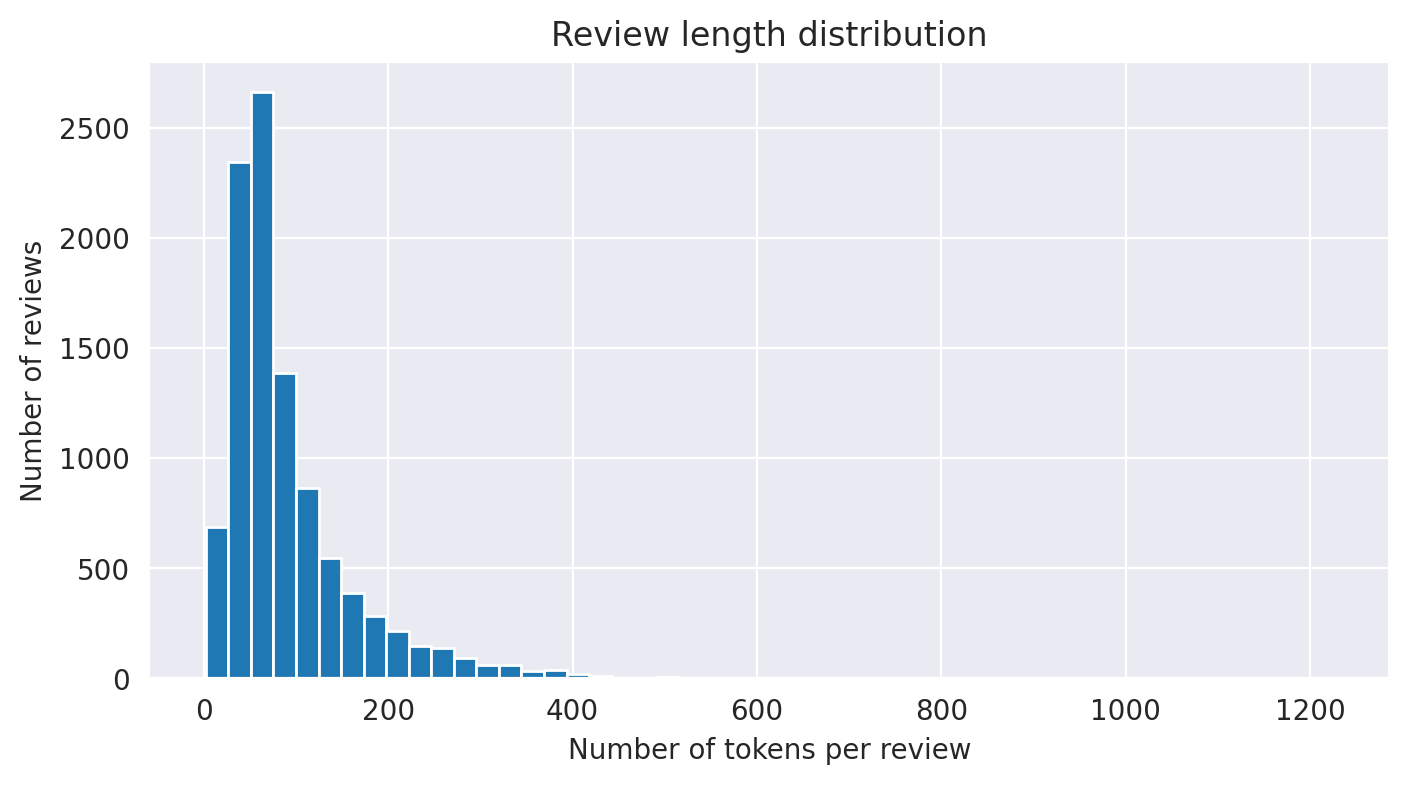

In [ ]:
#<SOL>
import numpy as np
import matplotlib.pyplot as plt

# Número de tokens de cada reseña
n_tokens = [len(doc) for doc in corpus]
print('Average number of tokens per review:', np.mean(n_tokens))

# Histograma de la longitud de las reseñas
plt.figure(figsize=(8, 4))
plt.hist(n_tokens, bins=50)
plt.xlabel('Number of tokens per review')
plt.ylabel('Number of reviews')
plt.title('Review length distribution')
plt.show()
#</SOL>

### *2.2. N-gram detection*

Gensim N-gram detection is purely based on the detection of tokens that appear next to each other with high frequency. Since we have already carried out lemmatization and stopword removal, we can use it in a very simple way.

Two parameters are necessary:
   - `min_count`: minimum number of occurrences of an N-gram to be considered
   - `threshold`: minimum score for accepting N-grams. Higher values imply that fewer N-grams are accepted. The score depends on the frequency of the N-gram, as well as on the number of isolated occurrences of the component tokens.

Note that the N-gram model is part of the preprocessing: any new text (e.g., a query) must be transformed with the same model.

In [ ]:
from gensim.models.phrases import Phrases

phrase_model = Phrases(corpus, min_count=2, threshold=20)

print(colored('\n============= First review in corpus =============', 'blue'))
print(corpus[0])
corpus = [el for el in phrase_model[corpus]] # We populate corpus again
print(colored('\n============= First review after N-gram replacement =============', 'blue'))
print(corpus[0])


============= First review in corpus =============
['wonderful', 'little', 'production', 'filming', 'technique', 'old', 'time', 'bbc', 'fashion', 'give', 'comforting', 'discomforte', 'sense', 'realism', 'entire', 'piece', 'actor', 'michael', 'sheen', 'get', 'polari', 'voice', 'pat', 'seamless', 'editing', 'guide', 'reference', 'williams', 'diary', 'entry', 'worth', 'watching', 'terrificly', 'write', 'perform', 'piece', 'masterful', 'production', 'great', 'master', 'comedy', 'life', 'realism', 'come', 'little', 'thing', 'fantasy', 'guard', 'use', 'traditional', 'dream', 'technique', 'remain', 'solid', 'disappear', 'play', 'knowledge', 'sens', 'scene', 'concern', 'orton', 'halliwell', 'set', 'flat', 'halliwell', 'mural', 'decorate', 'surface']

============= First review after N-gram replacement =============
['wonderful', 'little', 'production', 'filming', 'technique', 'old', 'time', 'bbc', 'fashion', 'give', 'comforting', 'discomforte', 'sense', 'realism', 'entire', 'piece', 'actor', 

Let's save the clean reviews for later use (Text Vectorization II): a text file with one review per line, and the dataframe with a new column.

In [ ]:
corpus_df['clean_review'] = [' '.join(doc) for doc in corpus]

with open(os.path.join(DATA_DIR, 'imdb_lemmas_clean.txt'), 'w', encoding='utf-8') as fout:
    for el in corpus_df['clean_review'].values.tolist():
        fout.write(el + '\n')

To be able to work with the corpus, we need to vectorize all its documents. To do so, there are two steps we need to carry out:

1. Calculate the dictionary
2. Transform the documents using the dictionary

### *2.3. Gensim dictionary*

As a first step for vectorizing documents, we need to create a dictionary containing all tokens in our text corpus and assign an integer identifier to each one of them.

The following code fragment generates such a dictionary and shows the first tokens in the dictionary.

In [ ]:
from gensim.corpora import Dictionary

# Create dictionary of tokens
D = Dictionary(corpus)
n_tokens = len(D)

print('The dictionary contains', n_tokens, 'terms')
print('First terms in the dictionary:')
for n in range(10):
    print(str(n), ':', D[n])

The dictionary contains 49410 terms
First terms in the dictionary:
0 : actor
1 : bbc
2 : come
3 : comedy
4 : comforting
5 : concern
6 : decorate
7 : diary
8 : disappear
9 : discomforte


The dictionary object contains several attributes and methods that can be useful for carrying out some cleaning tasks. You can check the available methods using

```
dir(D)
```

Some of the most useful methods that we will use are:

   - ```add_documents```: updates the dictionary processing new documents

   - ```merge_with```: merges two dictionaries

   - ```save```, ```save_as_text```, ```load```, ```load_from_text```: can be used to give persistence to the dictionary and reading a previously calculated dictionary

   - ```id2token```: This is a Python dictionary for the mapping tokenid (a number) -> token (text representation). You can check that ```D[n]``` is equivalent to ```D.id2token[n]```

   - ```token2id```: A Python dictionary for the reverse mapping token -> tokenid

   - ```items```, ```keys```, ```values```, ```iteritems```, ```iterkeys```, ```itervalues```: Can be used to obtain al items (tokenid, token), all tokenids, or all token texts, or to iterate over them.

   - ```dfs```: A Python dictionary for the mapping tokenid -> Number of documents where the token appears

   - ```filter_tokens```, ```filter_extremes```, ```filter_n_most_frequent```: are used to remove elements from the dictionary, and ```compactify```is used to reassign tokenids to tokens for a more efficient representation.

   - ```doc2bow```: converts a document into its Bag of Words Representation

   - ```doc2idx```: transforms a document into a sequence of the tokenids of the words of the document

##### **Exercise 8**

1. Obtain a dataframe with 2 columns: `token` and `ndocs`, corresponding to the text of each token and the number of documents where the token appears
2. Sort the dataframe according to column `ndocs`
3. How many tokens appear in exactly one document? Remove them from the dataframe
4. What are the most and least common tokens in the dictionary in terms of document occurrence?
5. Plot a histogram of the number of documents in which each token appears

Tokens in exactly one document: 19821 of 49410

Most common tokens:
       token  ndocs
0       good   4738
1       time   3665
2        see   3460
3      watch   3388
4      think   3148
5      story   3128
6  character   3078
7        bad   3076
8       look   2698
9       know   2685

Least common tokens (ndocs = 2):
            token  ndocs
29579   snatching      2
29580       chute      2
29581  intolerant      2
29582   singleton      2
29583      kibbee      2
29584  confection      2
29585   blackface      2
29586      chomps      2
29587      diwani      2
29588     aardman      2


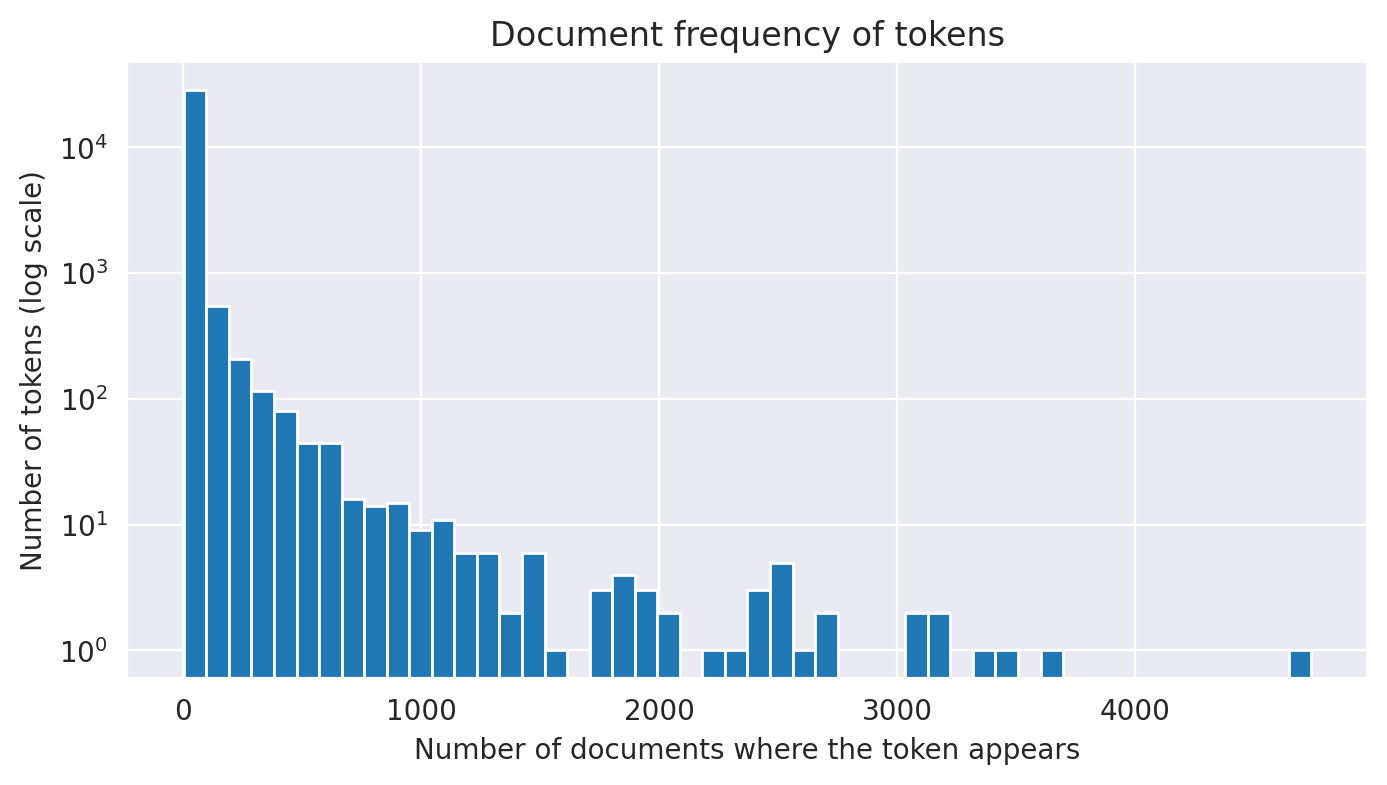

In [ ]:
#<SOL>
import pandas as pd
import matplotlib.pyplot as plt

# 1. Dataframe con cada token y el número de documentos donde aparece
df_tokens = pd.DataFrame([(D[tid], ndocs) for tid, ndocs in D.dfs.items()],
                         columns=['token', 'ndocs'])

# 2. Ordenamos de más a menos común
df_tokens = df_tokens.sort_values('ndocs', ascending=False).reset_index(drop=True)

# 3. Tokens que aparecen en un solo documento, y los quitamos
n_once = (df_tokens['ndocs'] == 1).sum()
print('Tokens in exactly one document:', n_once, 'of', len(df_tokens))
df_tokens = df_tokens[df_tokens['ndocs'] > 1]

# 4. Más y menos comunes
print('\nMost common tokens:')
print(df_tokens.head(10))
print('\nLeast common tokens (ndocs = 2):')
print(df_tokens.tail(10))

# 5. Histograma del número de documentos por token (eje y en escala log)
plt.figure(figsize=(8, 4))
plt.hist(df_tokens['ndocs'], bins=50, log=True)
plt.xlabel('Number of documents where the token appears')
plt.ylabel('Number of tokens (log scale)')
plt.title('Document frequency of tokens')
plt.show()
#</SOL>

Next, we will filter out terms that appear in too few or too many of the documents in the dataset. This makes sense because:

   - terms that appear in most documents are probably not very informative in the general context of a particular corpus
   - terms that appear in a very reduced number of documents are not useful to find repetitive patterns across documents. In fact, in many cases, we find that many of the words that are eliminated for this reason can be typos.

In [ ]:
no_below = 4 #Minimum number of documents to keep a term in the dictionary
no_above = .80 #Maximum proportion of documents in which a term can appear to be kept in the dictionary

D.filter_extremes(no_below=no_below,no_above=no_above)
n_tokens = len(D)

print('The dictionary contains', n_tokens, 'terms')

The dictionary contains 17749 terms


You can check dictionary size has been considerably reduced with respect to the original vocabulary.

### *2.4. Bag-of-Words (BoW)*

Next, let us create a numerical version of our corpus using the `doc2bow` method. In general, `D.doc2bow(token_list)` transforms any list of tokens into a list of tuples `(token_id, n)`, one per each token in `token_list`, where `token_id` is the token identifier (according to dictionary `D`) and `n` is the number of occurrences of such a token in `token_list`. Tokens that are not in the dictionary (e.g., those removed with `filter_extremes`) are ignored.

In [ ]:
reviews_bow = [D.doc2bow(doc) for doc in corpus]

n_review = 1000
print(colored('============= Review (lemmas) =============', 'blue'))
print(' '.join(corpus[n_review]))

print(colored('\n============= Sparse vector representation =============', 'blue'))
print(reviews_bow[n_review])

print(colored('\n============= Word counts for the review =============', 'blue'))
print(list(map(lambda x: (D[x[0]], x[1]), reviews_bow[n_review])))

============= Review (lemmas) =============
impressed nurse_betty way great ensemble character origional plot ending shoulda see come pull heart_string thing get morgan_freeman chris_rock interaction great warm_heart rock go crappy big hollywood fare lethal_weapon rest life freeman man need critique work hell kiss girl watchable renee zellwegger good role kinnear good obession sweet nice_touch gratuitous_violence satisfy bloodlust male outa

============= Sparse vector representation =============
[(2, 1), (16, 1), (18, 2), (23, 1), (47, 1), (58, 1), (72, 2), (74, 1), (81, 1), (105, 1), (129, 1), (148, 1), (175, 1), (206, 1), (216, 1), (239, 1), (279, 1), (302, 1), (322, 1), (328, 1), (375, 1), (781, 1), (944, 1), (950, 1), (1025, 1), (1041, 1), (1729, 1), (2398, 1), (2532, 1), (3535, 1), (3608, 1), (5415, 1), (5825, 1), (6116, 1), (6117, 1), (6511, 1), (9198, 1), (10251, 1), (11063, 1), (11180, 1), (11282, 1), (11283, 1), (11284, 1), (11285, 1), (11286, 1)]

============= Word counts 

Note that we can interpret each element of `reviews_bow` as a sparse vector. For example, a list of tuples

    [(0, 1), (3, 3), (5,2)]

for a dictionary of 10 elements can be represented as a vector, where any tuple `(id, n)` states that position `id` must take value `n`. The rest of the positions are zero.

    [1, 0, 0, 3, 0, 2, 0, 0, 0, 0]

As a summary, we have obtained the following variables that will be relevant for the next sections:

   * `D`: A Gensim dictionary. Term strings can be accessed using numeric identifiers. For instance, `D[0]` contains the string corresponding to the first position in the BoW representation.
   * `reviews_bow`: BoW corpus. A list containing an entry per review in the dataset, consisting of the (sparse) BoW representation of the review.

### *2.5. TF-IDF vectorization*

With its default options, Gensim computes the TF-IDF representation of a document as

$$x_{ij} = \text{count}_{ij} \log_2 \frac{\# docs}{\# docs_j}$$

and then normalizes each document vector to unit (L2) norm, where:

   - $x_{ij}$ is the component of the TF-IDF representation of document $i$ corresponding to term $j$
   - $\text{count}_{ij}$ is the number of occurrences of term $j$ in document $i$
   - $\# docs$ is the total number of documents in the corpus
   - ${\# docs_j}$ is the number of documents in the corpus containing term $j$

In this way, terms that appear in fewer documents get emphasized over common terms appearing in many documents, and the L2 normalization removes the effect of the document length. Note that this is not exactly the formula in the slides: libraries implement different variants (scikit-learn, for instance, uses a smoothed IDF).

Gensim offers the possibility to change the *term frequency* and *inverse document frequency* calculation terms, but we will keep the defaults.

Note that, contrary to the BoW representation, the TF-IDF representation does not depend just on the tokens of each document, but is affected by the whole corpus through the IDF factor.

Gensim considers TF-IDF as a model on its own and deals with it similarly to what is done with other models. Creating a TF-IDF model is very simple:

In [ ]:
from gensim.models import TfidfModel

tfidf = TfidfModel(reviews_bow)

A **TFIDF model cannot be updated** adding more documents. Otherwise, we would lose consistency, i.e., the TFIDF representation for a particular document would change before and after the TFIDF model gets updated.

From now on, `tfidf` can be used to convert any vector from the old representation (bow integer counts) to the new one (TFIDF real-valued weights), or to apply a transformation to a whole corpus

In [ ]:
reviews_tfidf = tfidf[reviews_bow]
print(colored('============= TF-IDF representation for the review =============', 'blue'))
print(reviews_tfidf[n_review])

print(colored('\n============= TF-IDF applying the transformation only to the document =============', 'blue'))
print(tfidf[reviews_bow[n_review]])

============= TF-IDF representation for the review =============
[(2, np.float64(0.04594697012235184)), (16, np.float64(0.04499057524626617)), (18, np.float64(0.09013628661922815)), (23, np.float64(0.055898018207204574)), (47, np.float64(0.04708300513995141)), (58, np.float64(0.1106268187215379)), (72, np.float64(0.04917258555225332)), (74, np.float64(0.0564420752163082)), (81, np.float64(0.07408907524024146)), (105, np.float64(0.03493291395739471)), (129, np.float64(0.03878355706305346)), (148, np.float64(0.07828388737809737)), (175, np.float64(0.07286191728184302)), (206, np.float64(0.19012692956469834)), (216, np.float64(0.04386094509456831)), (239, np.float64(0.04636167005597938)), (279, np.float64(0.05474920066899422)), (302, np.float64(0.0532717388835596)), (322, np.float64(0.09195077119697087)), (328, np.float64(0.09332355980427327)), (375, np.float64(0.15541346905731776)), (781, np.float64(0.09613148810958219)), (944, np.float64(0.11370706078549912)), (950, np.float64(0.0729222

As for BOW, TFIDF provides a sparse document representation.

### *2.6. Memory efficient computation*

In the previous examples, the construction of the dictionary and the transformation of the corpus to BoW or TFIDF format required that said corpus of documents be available in a list in the execution environment, and therefore required it to be stored in RAM. For a small corpus, this is not a problem, but it can be an important limitation when dealing with a large corpus with millions or tens of millions of documents. These corpora are becoming more and more common in certain applications (consider Wikipedia entries, user opinions on large e-commerce platforms, processing of medical records, etc.).

One of the advantages of Gensim is that its implementation makes it easy to work with a corpus of these sizes. As explained in the Gensim documentation:

> Note that the corpus above resides fully in memory, as a plain Python list. In this simple example, it doesn’t matter much, but just to make things clear, let’s assume there are millions of documents in the corpus. Storing all of them in RAM won’t do. Instead, let’s assume the documents are stored in a file on disk, one document per line. Gensim only requires that a corpus must be able to return one document vector at a time.

>The full power of Gensim comes from the fact that a corpus doesn’t have to be a list, a NumPy array, a Pandas dataframe, or whatever. Gensim accepts any object that, when iterated over, successively yields documents.

The next fragment of code illustrates how the dictionary can be created from a corpus stored in a text file. You just need to create an iterator that returns a document at each iteration and keeps adding documents to the dictionary. Note that during the execution of the code, only one document is kept in memory at every iteration.

In [ ]:
class IterableCorpus_fromfile:
    def __init__(self, filename):
        self.__filename = filename
    def __iter__(self):
        for line in open(self.__filename, encoding='utf-8'):
            # assume there's one document per line, tokens separated by whitespace
            yield line.lower()

MyIterCorpus = IterableCorpus_fromfile(os.path.join(DATA_DIR, 'imdb_lemmas_clean.txt'))
newD = Dictionary()
for doc in MyIterCorpus:
    newD.add_documents([doc.split()])
no_below = 4 # Minimum number of documents to keep a term in the dictionary
no_above = .80 # Maximum proportion of documents in which a term can appear to be kept in the dictionary
newD.filter_extremes(no_below=no_below, no_above=no_above)

The code above can be further simplified if the iterator already carries out the tokenization of each document. In that case, the dictionary can be created with a simple command:

In [ ]:
class IterableCorpus_fromfile:
    def __init__(self, filename):
        self.__filename = filename
    def __iter__(self):
        for line in open(self.__filename, encoding='utf-8'):
            # assume there's one document per line, tokens separated by whitespace
            yield line.lower().split()

MyIterCorpus = IterableCorpus_fromfile(os.path.join(DATA_DIR, 'imdb_lemmas_clean.txt'))
newD = Dictionary(MyIterCorpus)
no_below = 4 # Minimum number of documents to keep a term in the dictionary
no_above = .80 # Maximum proportion of documents in which a term can appear to be kept in the dictionary
newD.filter_extremes(no_below=no_below, no_above=no_above)

print('Number of documents processed:', newD.num_docs)
print('Number of elements in dictionary:', len(newD))

Number of documents processed: 10000
Number of elements in dictionary: 17749


### *2.7. Compatibility with NumPy and SciPy*

Gensim contains efficient functions to convert Gensim Corpus (BoW, TFIDF) to Numpy dense matrices or Scipy Sparse Matrices. This can be useful, e.g., if we wish to use the vectorial representation of a Gensim corpus to train a classification or regression model using sklearn.

Similarly, we also have functions to convert Numpy or Scipy matrices into Gensim representation.

More information on the available utilities can be found in the [Gensim API matutils documentation](https://radimrehurek.com/gensim/matutils.html).


Sklearn also includes functions for tokenization and vectorization of documents. Specifically, it has the functions:
* [`CountVectorizer`](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html#sklearn.feature_extraction.text.CountVectorizer) which implements both tokenization and word count (BoW) in a single class.
* [`TfidfTransformer`](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfTransformer.html#sklearn.feature_extraction.text.TfidfTransformer) which is responsible for obtaining the TF-IDF representation from a BoW representation.

* [`TfidfVectorizer`](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html#sklearn.feature_extraction.text.TfidfVectorizer) which is equivalent to using `CountVectorizer()` followed by `TfidfTransformer()`.

## **3. Sentiment Analysis with BoW and TF-IDF representations**
---

Let's start by obtaining binary labels for the problem.

In [ ]:
def get_binary_label(sentiment):
  return 1 if sentiment == "positive" else 0

corpus_df['binary_sentiment'] = corpus_df['sentiment'].apply(get_binary_label)

Y = corpus_df['binary_sentiment'].values
print(Y)

[1 1 1 ... 0 0 1]


And save the dataframe for later use (Text Vectorization II). The column `clean_review` contains the clean lemmas of each review, separated by blank spaces.

In [ ]:
corpus_df.to_csv(os.path.join(DATA_DIR, 'corpus_df_imdb.csv'), index=False)

Since we have carried out the vectorization with Gensim, we have to convert our vector representation into matrices so we can use scikit-learn classifiers. Gensim includes two functions for this: [corpus2dense](https://radimrehurek.com/gensim/matutils.html#gensim.matutils.corpus2dense) and [corpus2csc](https://radimrehurek.com/gensim/matutils.html#gensim.matutils.corpus2csc).

Keep the representation **sparse**: a dense matrix of 10,000 reviews by more than 10,000 terms takes hundreds of MB, while more than 99% of its entries are zero. Scikit-learn's linear models work directly with sparse matrices.

In [ ]:
from gensim.matutils import corpus2csc

n_tokens = len(D)
num_docs = len(reviews_bow)

# Sparse matrices (num_docs x n_tokens)
corpus_bow_sparse = corpus2csc(reviews_bow, num_terms=n_tokens, num_docs=num_docs).T.tocsr()
corpus_tfidf_sparse = corpus2csc(reviews_tfidf, num_terms=n_tokens, num_docs=num_docs).T.tocsr()

dense_MB = num_docs * n_tokens * 4 / 1e6
sparse_MB = (corpus_bow_sparse.data.nbytes + corpus_bow_sparse.indices.nbytes + corpus_bow_sparse.indptr.nbytes) / 1e6
print(f'Matrix shape: {corpus_bow_sparse.shape}')
print(f'Non-zero entries: {100 * corpus_bow_sparse.nnz / (num_docs * n_tokens):.2f}%')
print(f'Memory as a dense float32 matrix: {dense_MB:.0f} MB; as a sparse matrix: {sparse_MB:.1f} MB')

Matrix shape: (10000, 17749)
Non-zero entries: 0.37%
Memory as a dense float32 matrix: 710 MB; as a sparse matrix: 7.9 MB


##### **Exercise 9**

Train a logistic regression classifier (`LogisticRegression` from scikit-learn) with the BoW representation of the IMDB reviews:

* Use `train_test_split` to split the data with a $70/30$ ratio and `random_state=42`
* Find the best value of the regularization parameter `C` among `[0.01, 0.1, 1, 10]` via cross-validation with [`GridSearchCV`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html) (5 folds)
* Evaluate the classifier on the test set using the **accuracy** (method `score` of the classifier)

In [ ]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression

# <SOL>
# Partimos la matriz BoW y las etiquetas: 70% entrenamiento, 30% test
X_train, X_test, y_train, y_test = train_test_split(
    corpus_bow_sparse, Y, test_size=0.3, random_state=42)

# Buscamos el mejor C con validación cruzada de 5 folds (solo en entrenamiento)
param_grid = {'C': [0.01, 0.1, 1, 10]}
grid_bow = GridSearchCV(LogisticRegression(max_iter=1000), param_grid, cv=5)
grid_bow.fit(X_train, y_train)

print('Best C:', grid_bow.best_params_['C'])
print('CV accuracy (train):', round(grid_bow.best_score_, 4))

# Accuracy en test con el mejor modelo
print('Test accuracy:', round(grid_bow.score(X_test, y_test), 4))
# <\SOL>

Best C: 0.1
CV accuracy (train): 0.8423
Test accuracy: 0.849


##### **Exercise 10**

Repeat Exercise 9 with the TF-IDF representation. Which representation works better?

In [ ]:
# <SOL>
# Mismo split 70/30 y misma semilla, pero con la matriz TF-IDF
X_train_t, X_test_t, y_train_t, y_test_t = train_test_split(
    corpus_tfidf_sparse, Y, test_size=0.3, random_state=42)

# Mejor C con validación cruzada de 5 folds
grid_tfidf = GridSearchCV(LogisticRegression(max_iter=1000), param_grid, cv=5)
grid_tfidf.fit(X_train_t, y_train_t)

print('Best C:', grid_tfidf.best_params_['C'])
print('CV accuracy (train):', round(grid_tfidf.best_score_, 4))

# Accuracy en test con el mejor modelo
print('Test accuracy:', round(grid_tfidf.score(X_test_t, y_test_t), 4))

# Comparación con BoW
print('\nBoW   test accuracy:', round(grid_bow.score(X_test, y_test), 4))
print('TF-IDF test accuracy:', round(grid_tfidf.score(X_test_t, y_test_t), 4))
# </SOL>

Best C: 1
CV accuracy (train): 0.8543
Test accuracy: 0.858

BoW   test accuracy: 0.849
TF-IDF test accuracy: 0.858


## **4. Document retrieval with sparse representations**
---

In this section, we use the same representations to **search** the collection: given a query, rank the reviews by relevance. This is exactly what you will do in **Milestone 1** with your project corpus.

### *4.1. Test queries*

To evaluate a retrieval system we need a set of test queries and, for each of them, the documents that are relevant. File `imdb_queries.jsonl` contains 30 *known-item* queries: each query describes one specific review, which is the only one marked as relevant (`relevant_ids` contains its `id`).

The queries were **generated with an LLM** from randomly selected reviews, asking it to describe the review as a user searching for it would, avoiding copying its words. This is the approach you will follow in your project. A prompt like this one works well:

```
You will receive a movie review. Write a short search query (8-20 words) that a user
looking for THIS review could type. Describe its content with your own words: do not
copy phrases from the review, and avoid using names unless they are essential.
Review: <review text>
```

Two caveats you should keep in mind (and check manually on a sample of queries):
* LLMs tend to copy words from the document, which favors lexical methods such as BM25
* Other reviews might also be relevant for a query, but they count as errors

In [ ]:
with open(os.path.join(DATA_DIR, 'imdb_queries.jsonl'), encoding='utf-8') as f:
    queries = [json.loads(line) for line in f]

print(len(queries), 'queries')
for q in queries[:5]:
    print(q)

# Map from review id to row in corpus_df (and in all the representations above)
id2row = {review_id: row for row, review_id in enumerate(corpus_df['id'])}

30 queries
{'qid': 'q01', 'query': "musical whose release was blocked for years by the composer's heirs", 'relevant_ids': [9892]}
{'qid': 'q02', 'query': 'the 1990s animated Spider-Man series compared with the 1967 cartoon', 'relevant_ids': [19306]}
{'qid': 'q03', 'query': 'actress explains the entire storyline while dangling over a precipice in a laughably bad thriller', 'relevant_ids': [247]}
{'qid': 'q04', 'query': 'Alone in the Dark is worse than Alien vs Predator and a Razzie contender', 'relevant_ids': [12653]}
{'qid': 'q05', 'query': 'Orson Welles documentary about the art forger Elmyr and Clifford Irving', 'relevant_ids': [11133]}


The queries must be **preprocessed exactly like the documents**: same spaCy pipeline, same N-gram model, same dictionary.

In [ ]:
query_tokens = [phrase_model[tokens] for tokens in prepare_data([q['query'] for q in queries])]
for q, tokens in zip(queries[:5], query_tokens[:5]):
    print(q['query'], '->', tokens)

musical whose release was blocked for years by the composer's heirs -> ['musical', 'release', 'block', 'year', 'composer', 'heir']
the 1990s animated Spider-Man series compared with the 1967 cartoon -> ['animate', 'spider_man', 'series', 'compare', 'cartoon']
actress explains the entire storyline while dangling over a precipice in a laughably bad thriller -> ['actress', 'explain', 'entire', 'storyline', 'dangle', 'precipice', 'bad', 'thriller']
Alone in the Dark is worse than Alien vs Predator and a Razzie contender -> ['dark', 'bad', 'alien_predator', 'razzie', 'contender']
Orson Welles documentary about the art forger Elmyr and Clifford Irving -> ['orson_welles', 'documentary', 'art', 'forger', 'elmyr', 'clifford', 'irving']


### *4.2. Retrieval with TF-IDF and cosine similarity*

Gensim's `SparseMatrixSimilarity` computes the cosine similarity between a query vector and all the documents of an indexed corpus. Since our TF-IDF vectors have unit norm, this is just a dot product.

##### **Exercise 11**

Complete the function `retrieve_tfidf(tokens, k)`, which returns the row indices (in `corpus_df`) of the `k` documents most similar to a tokenized query, sorted by decreasing similarity. Use the dictionary `D`, the TF-IDF model `tfidf`, and the similarity index `index_tfidf`.

In [ ]:
import numpy as np
from gensim.similarities import SparseMatrixSimilarity

# Índice con los vectores TF-IDF de todas las reseñas
index_tfidf = SparseMatrixSimilarity(reviews_tfidf, num_features=len(D))

def retrieve_tfidf(tokens, k=10):
    #<SOL>
    # 1. La query pasa a BoW con el mismo diccionario (ignora palabras que no conoce)
    query_bow = D.doc2bow(tokens)
    # 2. De BoW a TF-IDF con el mismo modelo
    query_tfidf = tfidf[query_bow]
    # 3. Similitud coseno de la query con todas las reseñas
    sims = index_tfidf[query_tfidf]
    # 4. Filas de las k reseñas más similares, de mayor a menor
    top_k = np.argsort(-sims)[:k]
    return top_k.tolist()
    #</SOL>

q = 0
print(colored('Query: ' + queries[q]['query'], 'blue'))
for rank, row in enumerate(retrieve_tfidf(query_tokens[q], k=3), 1):
    print(f"{rank}. [id={corpus_df['id'].iloc[row]}] {corpus_df['review'].iloc[row][:200]}...")

Query: musical whose release was blocked for years by the composer's heirs
1. [id=29810] This is a beautiful, rich, and very well-executed film with a rich and meaningful story. Basically, it tells how an old master story teller needs to find a (male) heir to carry on his craft, but ends ...
2. [id=20570] Rosalind Russell executes a power-house performance as Rosie Lord, a very wealthy woman with greedy heirs. With an Auntie Mame-type character, this actress can never go wrong. Her very-real terror at ...
3. [id=14474] I own this video as well as the concert version of the musical with Patti Lupone and George Hearn with the San Francisco Symphony Orchestra. George Hearn is fantastic in my book as are Angela Lansbury...


### *4.3. Retrieval with BM25*

We will use the [`bm25s`](https://github.com/xhluca/bm25s) library, a fast implementation based on sparse matrices. It accepts our tokenized documents directly, so the preprocessing is the same as for TF-IDF. Remember the role of the two parameters:

* `k1` controls the **saturation** of the term frequency (typical values: 1.2–2)
* `b` controls the **document length normalization** (typical value: 0.75)

Note also that `bm25s` scores every token of the query: if a term is repeated in the query, its contribution is added twice.

In [ ]:
import bm25s

bm25 = bm25s.BM25(k1=1.5, b=0.75)
bm25.index(corpus, show_progress=False)

def retrieve_bm25(tokens, k=10, model=bm25):
    rows, scores = model.retrieve([tokens], k=k, show_progress=False)
    return rows[0].tolist()

q = 0
print(colored('Query: ' + queries[q]['query'], 'blue'))
for rank, row in enumerate(retrieve_bm25(query_tokens[q], k=3), 1):
    print(f"{rank}. [id={corpus_df['id'].iloc[row]}] {corpus_df['review'].iloc[row][:200]}...")

DEBUG:bm25s:Building index from tokens


Query: musical whose release was blocked for years by the composer's heirs
1. [id=14474] I own this video as well as the concert version of the musical with Patti Lupone and George Hearn with the San Francisco Symphony Orchestra. George Hearn is fantastic in my book as are Angela Lansbury...
2. [id=43177] Yes, I realize that half a dozen other reviewers have called this movie "Copying Amadeus", but it cannot be said enough. Scenes seemed to have been lifted directly from Milos Forman's script with only...
3. [id=31817] The Captain and Tennille have released a very good 3 DVD package with minimal editing. Unlike most variety show releases these shows have not been hacked to bits. The musical and dance numbers are inc...


### *4.4. Evaluation: Recall@K and MRR*

##### **Exercise 12**

Implement the functions `recall_at_k` and `mrr`. Both receive a list of rankings (one list of retrieved row indices per query, sorted by decreasing relevance) and a list with the sets of relevant row indices of each query:

* **Recall@K**: fraction of the relevant documents of each query found among the top $K$ results, averaged over queries
* **MRR**: average over queries of $1/\text{rank}$ of the first relevant document (0 if none is retrieved)

Then, evaluate TF-IDF and BM25 with $K=10$. Which queries are missed by both methods? Why?

In [ ]:
relevant = [set(id2row[i] for i in q['relevant_ids']) for q in queries]

def recall_at_k(rankings, relevant, k=10):
    #<SOL>
    # Para cada query: relevantes encontrados en el top k / relevantes totales
    recalls = []
    for ranking, rel in zip(rankings, relevant):
        found = len(set(ranking[:k]) & rel)
        recalls.append(found / len(rel))
    return np.mean(recalls)
    #</SOL>

def mrr(rankings, relevant):
    #<SOL>
    # Para cada query: 1/posición del primer relevante (0 si no aparece)
    rr = []
    for ranking, rel in zip(rankings, relevant):
        score = 0
        for rank, row in enumerate(ranking, 1):
            if row in rel:
                score = 1 / rank
                break
        rr.append(score)
    return np.mean(rr)
    #</SOL>

#<SOL>
K = 10
# Rankings de cada método para las 30 queries
rank_tfidf = [retrieve_tfidf(tokens, k=K) for tokens in query_tokens]
rank_bm25 = [retrieve_bm25(tokens, k=K) for tokens in query_tokens]

print(f"TF-IDF -> Recall@{K}: {recall_at_k(rank_tfidf, relevant, K):.3f} | MRR: {mrr(rank_tfidf, relevant):.3f}")
print(f"BM25   -> Recall@{K}: {recall_at_k(rank_bm25, relevant, K):.3f} | MRR: {mrr(rank_bm25, relevant):.3f}")

# Queries que no encuentran su reseña en el top K con ninguno de los dos métodos
print('\nQueries missed by both methods:')
for i, q in enumerate(queries):
    if not (set(rank_tfidf[i]) & relevant[i]) and not (set(rank_bm25[i]) & relevant[i]):
        print(q['qid'], '-', q['query'])
#</SOL>

TF-IDF -> Recall@10: 0.733 | MRR: 0.583
BM25   -> Recall@10: 0.800 | MRR: 0.709

Queries missed by both methods:
q01 - musical whose release was blocked for years by the composer's heirs
q09 - German director's 1970s film imagining simulated worlds decades before modern science fiction
q12 - French comedy mocking the acting profession that ends with the director talking to his dead father on the phone
q15 - filmmaker forced to shoot a dumb teen comedy to settle his tax problems
q21 - teenage girl pretends to be her twin brother to join the boys' football team
q28 - a girl searches for her friend taken away by an ice queen


In [ ]:
# Para cada query fallada por ambos métodos: reseña relevante y palabras compartidas
missed_ids = ['q01', 'q09', 'q12', 'q15', 'q21', 'q28']
for i, q in enumerate(queries):
    if q['qid'] in missed_ids:
        row = next(iter(relevant[i]))
        shared = set(query_tokens[i]) & set(corpus[row])
        print(colored(q['qid'] + ' - ' + q['query'], 'blue'))
        print('Query tokens :', query_tokens[i])
        print('Shared tokens:', shared)
        print('Relevant review:', corpus_df['review'].iloc[row][:300], '...\n')

q01 - musical whose release was blocked for years by the composer's heirs
Query tokens : ['musical', 'release', 'block', 'year', 'composer', 'heir']
Shared tokens: {'year', 'release'}
Relevant review: I have searched for this movie for years. I have great memories of the first-rate acting and singing in this movie. I never knew that the reason the movie was unobtainable was because of the actions of the Gershwin family -- SHAME ON THEM for trying to suppress at American Classic!! I can only hope  ...

q09 - German director's 1970s film imagining simulated worlds decades before modern science fiction
Query tokens : ['german', 'director', 'imagine', 'simulate', 'world', 'decade', 'modern', 'science_fiction']
Shared tokens: set()
Relevant review: In these days of ultra-fast processors and the Internet, coming up with a movie like "The Matrix" may seem merely the next step from coining the term 'cyberspace', but do you remember what computers were like in 1974? Right. To come up with the n

##### **Exercise 13**

Evaluate BM25 with different values of `k1` (e.g., 0.5, 1.2, 2) and `b` (e.g., 0, 0.5, 0.75, 1). Do the results change much? What does `b = 0` mean?

In [ ]:
#<SOL>
import pandas as pd

k1_values = [0.5, 1.2, 2]
b_values = [0, 0.5, 0.75, 1]

results = []
for k1 in k1_values:
    for b in b_values:
        # Un índice BM25 por cada combinación de k1 y b
        model = bm25s.BM25(k1=k1, b=b)
        model.index(corpus, show_progress=False)
        rankings = [retrieve_bm25(tokens, k=10, model=model) for tokens in query_tokens]
        results.append({'k1': k1, 'b': b,
                        'Recall@10': recall_at_k(rankings, relevant, 10),
                        'MRR': mrr(rankings, relevant)})

df_bm25 = pd.DataFrame(results)
print(df_bm25.round(3).to_string(index=False))
#</SOL>

DEBUG:bm25s:Building index from tokens
DEBUG:bm25s:Building index from tokens
DEBUG:bm25s:Building index from tokens
DEBUG:bm25s:Building index from tokens
DEBUG:bm25s:Building index from tokens
DEBUG:bm25s:Building index from tokens
DEBUG:bm25s:Building index from tokens
DEBUG:bm25s:Building index from tokens
DEBUG:bm25s:Building index from tokens
DEBUG:bm25s:Building index from tokens
DEBUG:bm25s:Building index from tokens
DEBUG:bm25s:Building index from tokens


 k1    b  Recall@10   MRR
0.5 0.00      0.733 0.678
0.5 0.50      0.800 0.726
0.5 0.75      0.800 0.750
0.5 1.00      0.800 0.736
1.2 0.00      0.733 0.669
1.2 0.50      0.800 0.726
1.2 0.75      0.800 0.714
1.2 1.00      0.800 0.697
2.0 0.00      0.733 0.653
2.0 0.50      0.800 0.710
2.0 0.75      0.800 0.699
2.0 1.00      0.800 0.691


---
In this notebook, we have covered the preprocessing steps that need to be applied to a text corpus before its vectorization, and we have obtained BoW and TF-IDF representations with Gensim. We have used them for two tasks: sentiment analysis, and document retrieval with TF-IDF and BM25.

Note the kind of queries that sparse methods miss: those that describe the content with **different words** from the ones used in the review. Dense representations (word and sentence embeddings, next sessions) aim at capturing meaning beyond exact word matches. In Milestone 2, you will compare them with the baseline you build in Milestone 1.